# 🔍 02 · Validate & explore the data
### Validar y explorar los datos

| | |
|---|---|
| 🍳 **Analogy / Analogía** | *Checking the ingredients aren't rotten* · *Revisar que los ingredientes no estén podridos* |
| 🎯 **Goal / Objetivo** | Make sure the data is healthy and understand it · Asegurar que los datos estén sanos y entenderlos |
| 🏭 **Becomes / Se convierte en** | `src/data/validate.py` + `tests/test_data.py` |

> **Garbage in → garbage out.** A model trained on broken data learns broken patterns.
> **Basura entra → basura sale.** Un modelo entrenado con datos rotos aprende patrones rotos.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["figure.figsize"] = (11, 4)
path = "data/raw/xauusd_h1.csv" if Path("data/raw/xauusd_h1.csv").exists() else "data/sample/xauusd_h1_sample.csv"
df = pd.read_csv(path, parse_dates=["time"])
print(path, df.shape)
df.describe().round(2)

data/raw/xauusd_h1.csv (29999, 7)


,time,open,high,low,close,volume,spread
count,29999,29999.00,29999.00,29999.00,29999.00,29999.00,29999.00
mean,2024-03-14 22:40:32.601086720,2667.58,2671.97,2663.03,2667.66,7800.38,29.39
min,2021-08-31 18:00:00,1616.56,1620.28,1614.71,1616.57,139.00,23.00
25%,2022-12-06 06:30:00,1872.64,1874.76,1870.38,1872.61,3378.00,25.00
50%,2024-03-14 05:00:00,2160.94,2163.22,2158.48,2161.02,5993.00,27.00
75%,2025-06-23 01:30:00,3337.30,3341.34,3332.78,3337.30,10733.50,31.00
max,2026-09-29 05:00:00,5562.43,5597.84,5554.58,5562.30,38656.00,90.00
std,NaN,1013.89,1017.11,1010.39,1013.91,5940.39,5.23


## 1️⃣ Health checks / Chequeos de salud
Each check is a simple True/False question. / Cada chequeo es una pregunta de Sí/No.

In [2]:
checks = {
    "no missing values / sin vacíos": df.isna().sum().sum() == 0,
    "no duplicated hours / sin horas duplicadas": not df["time"].duplicated().any(),
    "time is sorted / tiempo ordenado": df["time"].is_monotonic_increasing,
    "prices > 0": (df[["open", "high", "low", "close"]] > 0).all().all(),
    "high is the highest / high es el máximo": (df["high"] >= df[["open", "close", "low"]].max(axis=1)).all(),
    "low is the lowest / low es el mínimo": (df["low"] <= df[["open", "close", "high"]].min(axis=1)).all(),
}
for k, v in checks.items():
    print("✅" if v else "❌", k)

✅

 no missing values / sin vacíos
✅ no duplicated hours / sin horas duplicadas
✅ time is sorted / tiempo ordenado
✅ prices > 0
✅ high is the highest / high es el máximo
✅ low is the lowest / low es el mínimo


## 2️⃣ Gaps in time: weekends! / Huecos en el tiempo: ¡fines de semana!
**EN:** Gold doesn't trade on weekends, so there are "jumps" of ~48h. That's normal, not an error.
**ES:** El oro no cotiza los fines de semana: hay "saltos" de ~48h. Es normal, no es un error.

In [3]:
gaps = df["time"].diff().dt.total_seconds().div(3600)
print(gaps.value_counts().head(6).rename("count of gaps (hours)"))

time
1.0     28687
2.0      1009
50.0      227
4.0        31
49.0       10
74.0        9
Name: count of gaps (hours), dtype: int64


## 3️⃣ Up or down? Is the target balanced? / ¿Sube o baja? ¿Está balanceado?

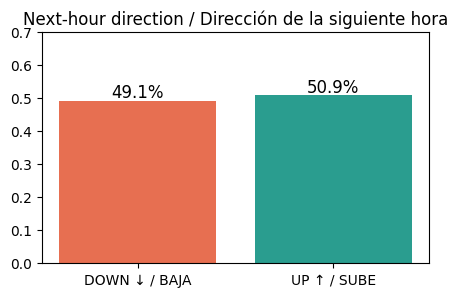

In [4]:
up = (df["close"].shift(-1) > df["close"]).mean()
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["DOWN ↓ / BAJA", "UP ↑ / SUBE"], [1 - up, up], color=["#e76f51", "#2a9d8f"])
ax.set_ylim(0, 0.7)
for i, v in enumerate([1 - up, up]):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center", fontsize=12)
ax.set_title("Next-hour direction / Dirección de la siguiente hora")
plt.show()

**EN:** ~50/50. This means a model that "always says UP" is already right ~51% of the time.
That's our **baseline**: any real model must beat it.

**ES:** ~50/50. Un modelo que "siempre dice SUBE" ya acierta ~51% de las veces.
Esa es nuestra **línea base (baseline)**: cualquier modelo real debe superarla.

## 4️⃣ Is the price predictable at all? / ¿El precio es predecible?
**Autocorrelation:** does the last hour's move tell us anything about the next one?
**Autocorrelación:** ¿el movimiento de la última hora nos dice algo de la siguiente?

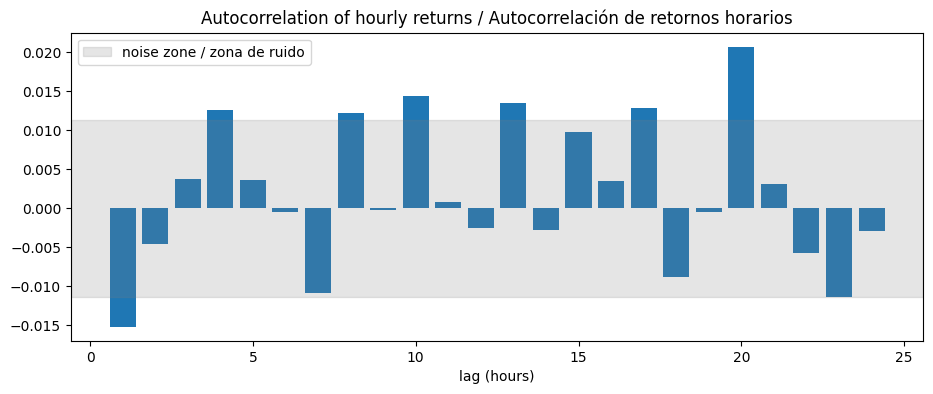

In [5]:
ret = df["close"].pct_change().dropna()
lags = range(1, 25)
ac = [ret.autocorr(lag) for lag in lags]
fig, ax = plt.subplots()
ax.bar(lags, ac, color="#1f77b4")
band = 1.96 / np.sqrt(len(ret))
ax.axhspan(-band, band, color="grey", alpha=0.2, label="noise zone / zona de ruido")
ax.set_xlabel("lag (hours)")
ax.set_title("Autocorrelation of hourly returns / Autocorrelación de retornos horarios")
ax.legend()
plt.show()

**EN:** Almost all bars are inside the grey "noise zone" → hourly gold moves are **close to random**.
Expect accuracy around **51–53%**, not 90%. If you ever see 90%, suspect **data leakage** (notebook 03).

**ES:** Casi todas las barras están en la "zona de ruido" gris → los movimientos horarios del oro son
**casi aleatorios**. Espera un acierto de **51–53%**, no 90%. Si ves 90%, sospecha **data leakage** (notebook 03).

## 5️⃣ When does gold move? / ¿Cuándo se mueve el oro?

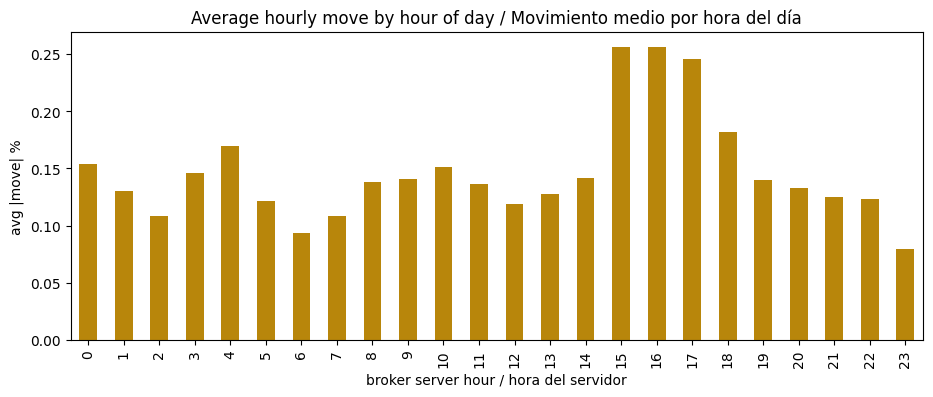

In [6]:
df["abs_ret"] = df["close"].pct_change().abs() * 100
by_hour = df.groupby(df["time"].dt.hour)["abs_ret"].mean()
fig, ax = plt.subplots()
by_hour.plot.bar(ax=ax, color="#b8860b")
ax.set_xlabel("broker server hour / hora del servidor")
ax.set_ylabel("avg |move| %")
ax.set_title("Average hourly move by hour of day / Movimiento medio por hora del día")
plt.show()

**EN:** The big spikes are the **London open** and the **New York open / US data releases**.
That's why we'll give the model the "hour of day" as a clue.

**ES:** Los picos son la **apertura de Londres** y la **apertura de Nueva York / datos de EE.UU.**
Por eso le daremos al modelo la "hora del día" como pista.

---
## 🔁 From notebook to production / Del notebook a producción

| Notebook cell | Production |
|---|---|
| `checks = {...}` dictionary | `run_checks()` in `src/data/validate.py` |
| We *look* at ✅/❌ | The pipeline **stops** (exit code 1) if any check fails |
| — | `tests/test_data.py` proves the checks catch broken candles and duplicates |
| — | Result saved to `reports/data_validation.json` (a DVC stage) |